In [1]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from scipy import linalg

%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 9)

## using matplotlib with image files

**https://matplotlib.org/tutorials/introductory/images.html**

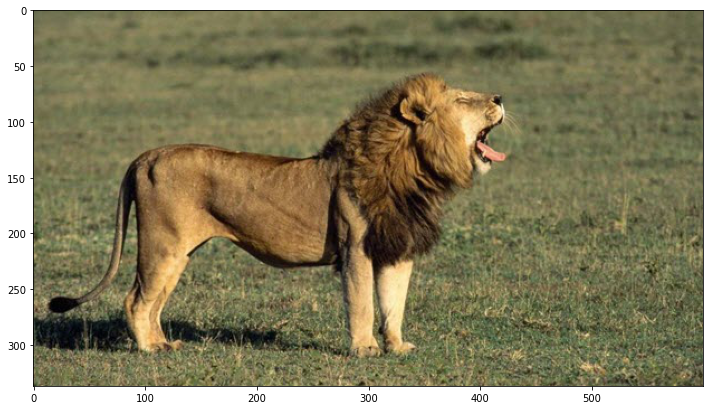

In [2]:
#read and show image
path = 'lion.jpeg'
img = mpimg.imread(path)
imgplot = plt.imshow(img)

In [3]:
# type and shape
type(img)

numpy.ndarray

In [4]:
img.shape

(337, 600, 3)

In [5]:
# take a look at img
img

array([[[ 91,  97,  69],
        [ 92,  98,  70],
        [ 93,  99,  71],
        ...,
        [108, 107,  76],
        [105, 104,  73],
        [105, 102,  71]],

       [[ 93,  99,  71],
        [ 94, 100,  72],
        [ 95, 101,  73],
        ...,
        [108, 107,  76],
        [106, 105,  74],
        [107, 104,  73]],

       [[ 96, 102,  74],
        [ 97, 103,  75],
        [ 98, 104,  76],
        ...,
        [108, 107,  76],
        [108, 107,  76],
        [110, 107,  76]],

       ...,

       [[ 98,  97,  67],
        [ 99, 104,  72],
        [ 94, 105,  71],
        ...,
        [ 84,  79,  50],
        [105, 100,  71],
        [110, 104,  78]],

       [[ 66,  65,  35],
        [ 77,  82,  50],
        [ 71,  85,  50],
        ...,
        [ 89,  83,  57],
        [ 83,  77,  51],
        [ 95,  89,  63]],

       [[ 63,  66,  47],
        [ 49,  57,  34],
        [ 55,  68,  40],
        ...,
        [ 90,  74,  51],
        [ 78,  66,  42],
        [ 73,  67,  41]]

In [7]:
# creat a new image with the same dimension as img
dimensions = img.shape
print(dimensions)
img1 = np.zeros(dimensions, int)
img1.shape

(337, 600, 3)


(337, 600, 3)

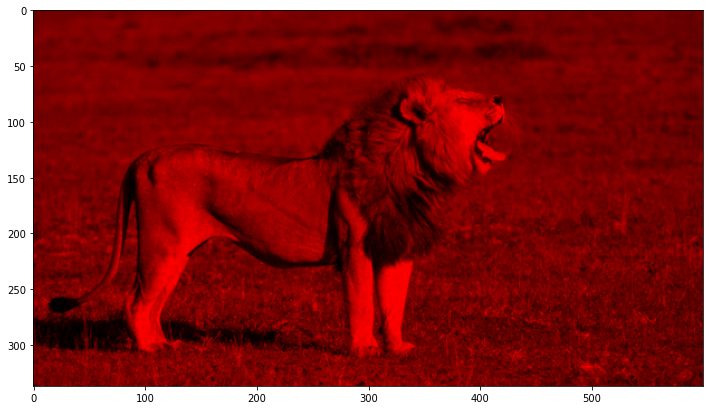

In [8]:
# get the red component of the image
for i in range(dimensions[0]):
    for j in range(dimensions[1]):
        img1[i][j][0] = img[i][j][0]
imgplot = plt.imshow(img1)

In [9]:
# compare img and img1
img

array([[[ 91,  97,  69],
        [ 92,  98,  70],
        [ 93,  99,  71],
        ...,
        [108, 107,  76],
        [105, 104,  73],
        [105, 102,  71]],

       [[ 93,  99,  71],
        [ 94, 100,  72],
        [ 95, 101,  73],
        ...,
        [108, 107,  76],
        [106, 105,  74],
        [107, 104,  73]],

       [[ 96, 102,  74],
        [ 97, 103,  75],
        [ 98, 104,  76],
        ...,
        [108, 107,  76],
        [108, 107,  76],
        [110, 107,  76]],

       ...,

       [[ 98,  97,  67],
        [ 99, 104,  72],
        [ 94, 105,  71],
        ...,
        [ 84,  79,  50],
        [105, 100,  71],
        [110, 104,  78]],

       [[ 66,  65,  35],
        [ 77,  82,  50],
        [ 71,  85,  50],
        ...,
        [ 89,  83,  57],
        [ 83,  77,  51],
        [ 95,  89,  63]],

       [[ 63,  66,  47],
        [ 49,  57,  34],
        [ 55,  68,  40],
        ...,
        [ 90,  74,  51],
        [ 78,  66,  42],
        [ 73,  67,  41]]

In [ ]:
img1

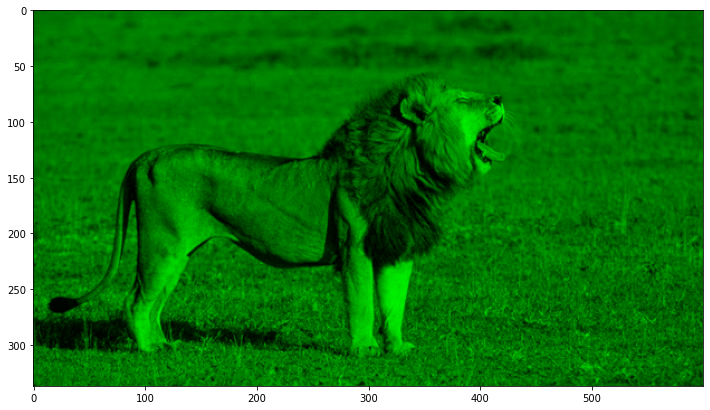

In [13]:
# get the green component of the image
img2 = np.zeros(dimensions, int)
for i in range(dimensions[0]):
    for j in range(dimensions[1]):
        img2[i][j][1] = img[i][j][1]
imgplot = plt.imshow(img2)

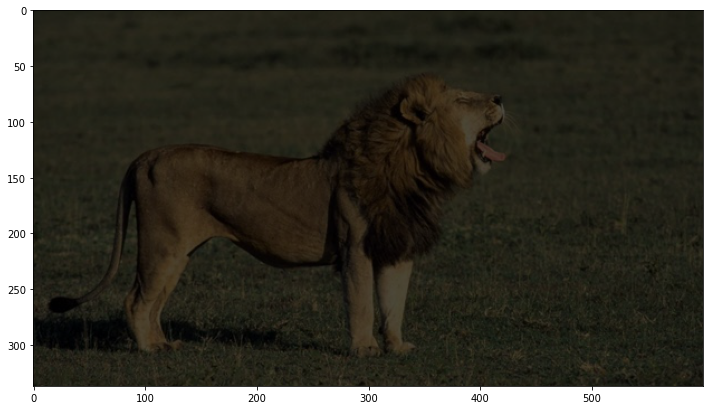

In [14]:
# change the intensity of the image
p = 0.3
img4 = np.zeros(dimensions, int)
for i in range(dimensions[0]):
    for j in range(dimensions[1]):
        for k in range(dimensions[2]):
            img4[i][j][k] = img[i][j][k] * p
mgplot = plt.imshow(img4)


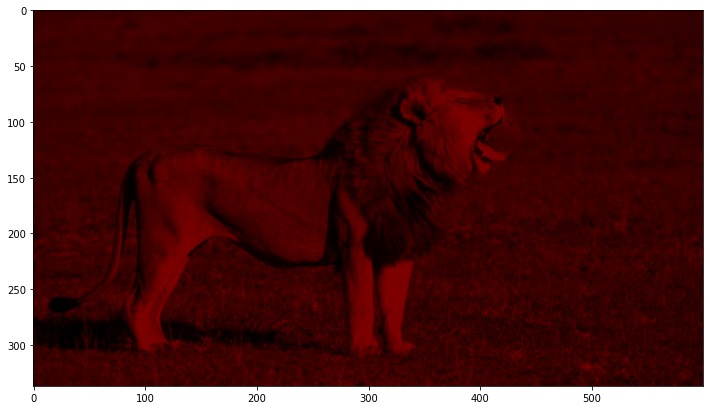

In [15]:
# dim the red image
p = 0.5
img5 = np.zeros(dimensions, int)
for i in range(dimensions[0]):
    for j in range(dimensions[1]):
        for k in range(dimensions[2]):
            img5[i][j][k] = img1[i][j][k] * p
mgplot = plt.imshow(img5)

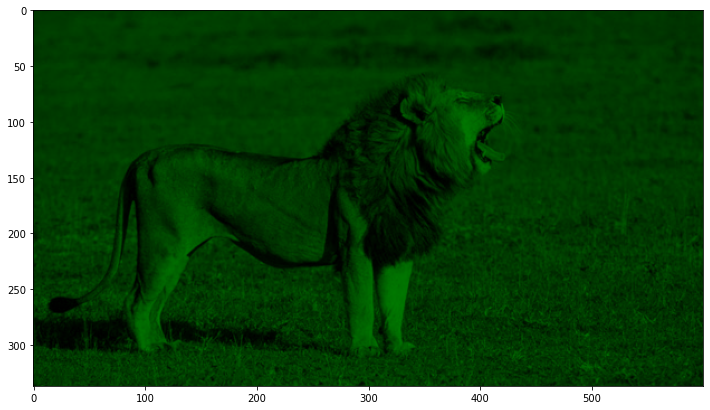

In [16]:
#dim the green image
p = 0.5
img6 = np.zeros(dimensions, int)
for i in range(dimensions[0]):
    for j in range(dimensions[1]):
        for k in range(dimensions[2]):
            img6[i][j][k] = img2[i][j][k] * p
mgplot = plt.imshow(img6)

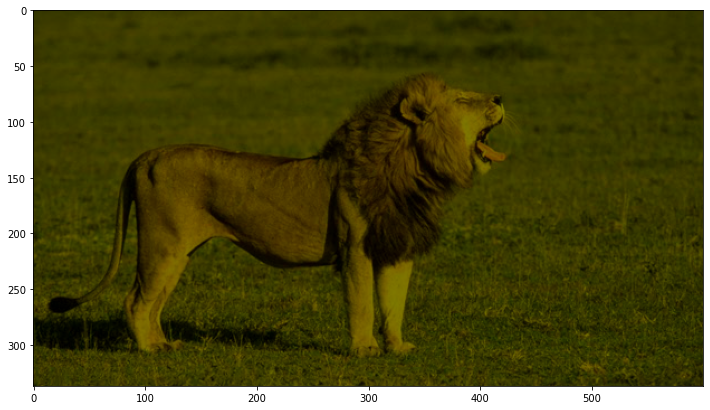

In [17]:
#combine dimmed red and green images
img7 = np.zeros(dimensions, int)
img7 = img5 + img6
mgplot = plt.imshow(img7)

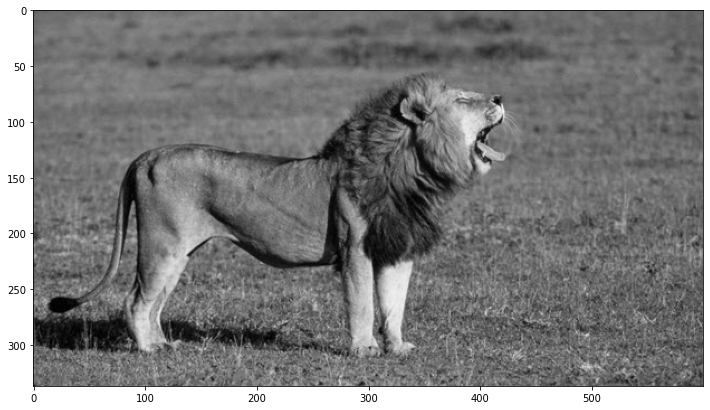

In [18]:
def rgb2gray(rgb):
    return np.dot(rgb[...,:3], [0.2989,0.5870,0.1140])

img_gray = rgb2gray(img)
img_re = np.zeros(img.shape)
img_re[:,:,0] = img_gray #R
img_re[:,:,1] = img_gray #G
img_re[:,:,2] = img_gray #B
img_re = img_re.astype(int)
plt.imshow(img_re)

## Singular Value Decomposition
### General format
$$
\Large
A=U\Sigma V^T=
[u_1,u_2,\dots,u_k]
\begin{bmatrix} 
\sigma_1 & 0 & 0 & 0\\
0 & \sigma_2 & 0 & 0\\ 
0 & 0        & \dots & 0\\
0 & 0        &  0    & \sigma_k
\end{bmatrix}
[v_1,v_2,\dots,v_k]^T
$$
where $u_1,\dots,u_k$ are column vectors with size $n$, and $v_1,\dots,v_k$ are column vectors with size $m$. $\sigma_1\dots,\sigma_k\geq0$.

Also, $u_i^Tu_j=0$ for any $i\neq j$, and $||u_i||=1$. $v_i^Tv_j=0$ for any $i\neq j$, and $||v_i||=1$. (Orthogonality)

where $U$ has size $n\times k$, $\Sigma$ has size $k\times k$, and $V$ has size $m\times k$ ($k\leq n,m$).

### other form
singular value decomposition as sum of vector product
$$
\Large
A=U\Sigma V^T=
[u_1,u_2,\dots,u_k]
\begin{bmatrix} 
\sigma_1 & 0 & 0 & 0\\
0 & \sigma_2 & 0 & 0\\ 
0 & 0        & \dots & 0\\
0 & 0        &  0    & \sigma_k
\end{bmatrix}
[v_1,v_2,\dots,v_k]^T
$$
$$
\Large
=
[\sigma_1 u_1,\dots,\sigma_ku_k]
[v_1,v_2,\dots,v_k]^T
=
\sum_i \sigma_iu_iv_i^T
$$


**This form is useful for low-rank approximation**.

reference: 
https://en.wikipedia.org/wiki/Singular_value_decomposition

### Why low-rank approximation? a mathematical explaination
Similarly, for Singular Value Decomposition,
$$A=U\Sigma V^T=\sum_i\sigma_iu_iv_i^T.$$
Let's assume singular values are ordered as $\sigma_1\geq\sigma_2\geq\dots\geq\sigma_k>0$.

If there exists $\sigma_1,\dots,\sigma_r\gg\sigma_{r+1}\dots\sigma_k>0$.
Then

$$
A\approx\sum_{1\leq i\leq r}\sigma_iu_iv_i^T.
$$

## obtain SVD using scipy

### quick introduction to Scipy
https://www.scipy.org/install.html

https://www.scipy.org/getting-started.html

### extract SVD using svd function
reference: https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.svd.html

In [ ]:
new_matr = np.array([[1,2,3],[4,5,6],[7,8,9]])
print(new_matr,"\n\n")
U, s, Vh = linalg.svd(new_matr, full_matrices=False)
print(U,"\n")
print(s,"\n")
print(Vh,"\n")


In [ ]:
print(img_gray.shape)

In [ ]:
# perform SVD by scipy
U, s, Vh = linalg.svd(img_gray, full_matrices=False)
print(U.shape)
print(s.shape)
print(Vh.shape)

In [ ]:
# order sigma values from large -> small
indices = np.argsort(-s)  # numpy argsort sort from small -> large
# reorder
U_sorted = U[:,indices]
Vh_sorted = Vh[indices,:]
s_sorted = s[indices]

In [ ]:
print(s_sorted[:20])

In [ ]:
print(s_sorted[-10:])

In [ ]:
# 10-rank approximation
rank = 40
img_rank_10 = U_sorted[:,:rank] @ np.diag(s_sorted[:rank]) @ Vh[:rank,:]  #@ symbol denotes matrix multiplication
print(img_rank_10)

In [ ]:
# copy to RGB
img_rank_10_rgb = np.round(np.zeros(list(img_rank_10.shape)+[3])).astype(int)
img_rank_10_rgb[:,:,0] = img_rank_10 #R
img_rank_10_rgb[:,:,1] = img_rank_10 #G
img_rank_10_rgb[:,:,2] = img_rank_10 #B

print(img_rank_10_rgb)

In [ ]:
plt.imshow(img_rank_10_rgb)